In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

sns.set_theme(style="whitegrid")

In [29]:
df = pd.read_csv("wine.csv")
df.head()

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [30]:
df.shape

(178, 14)

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Type             178 non-null    int64  
 1   Alcohol          178 non-null    float64
 2   Malic            178 non-null    float64
 3   Ash              178 non-null    float64
 4   Alcalinity       178 non-null    float64
 5   Magnesium        178 non-null    int64  
 6   Phenols          178 non-null    float64
 7   Flavanoids       178 non-null    float64
 8   Nonflavanoids    178 non-null    float64
 9   Proanthocyanins  178 non-null    float64
 10  Color            178 non-null    float64
 11  Hue              178 non-null    float64
 12  Dilution         178 non-null    float64
 13  Proline          178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [32]:
df.describe().round(2)

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,1.94,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.78,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,1.00,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,1.00,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,2.00,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,3.00,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,3.00,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


In [33]:
df["Type"].value_counts().sort_index()

Type
1    59
2    71
3    48
Name: count, dtype: int64

In [34]:
df.isnull().sum()

Type               0
Alcohol            0
Malic              0
Ash                0
Alcalinity         0
Magnesium          0
Phenols            0
Flavanoids         0
Nonflavanoids      0
Proanthocyanins    0
Color              0
Hue                0
Dilution           0
Proline            0
dtype: int64

In [35]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## Feature distributions

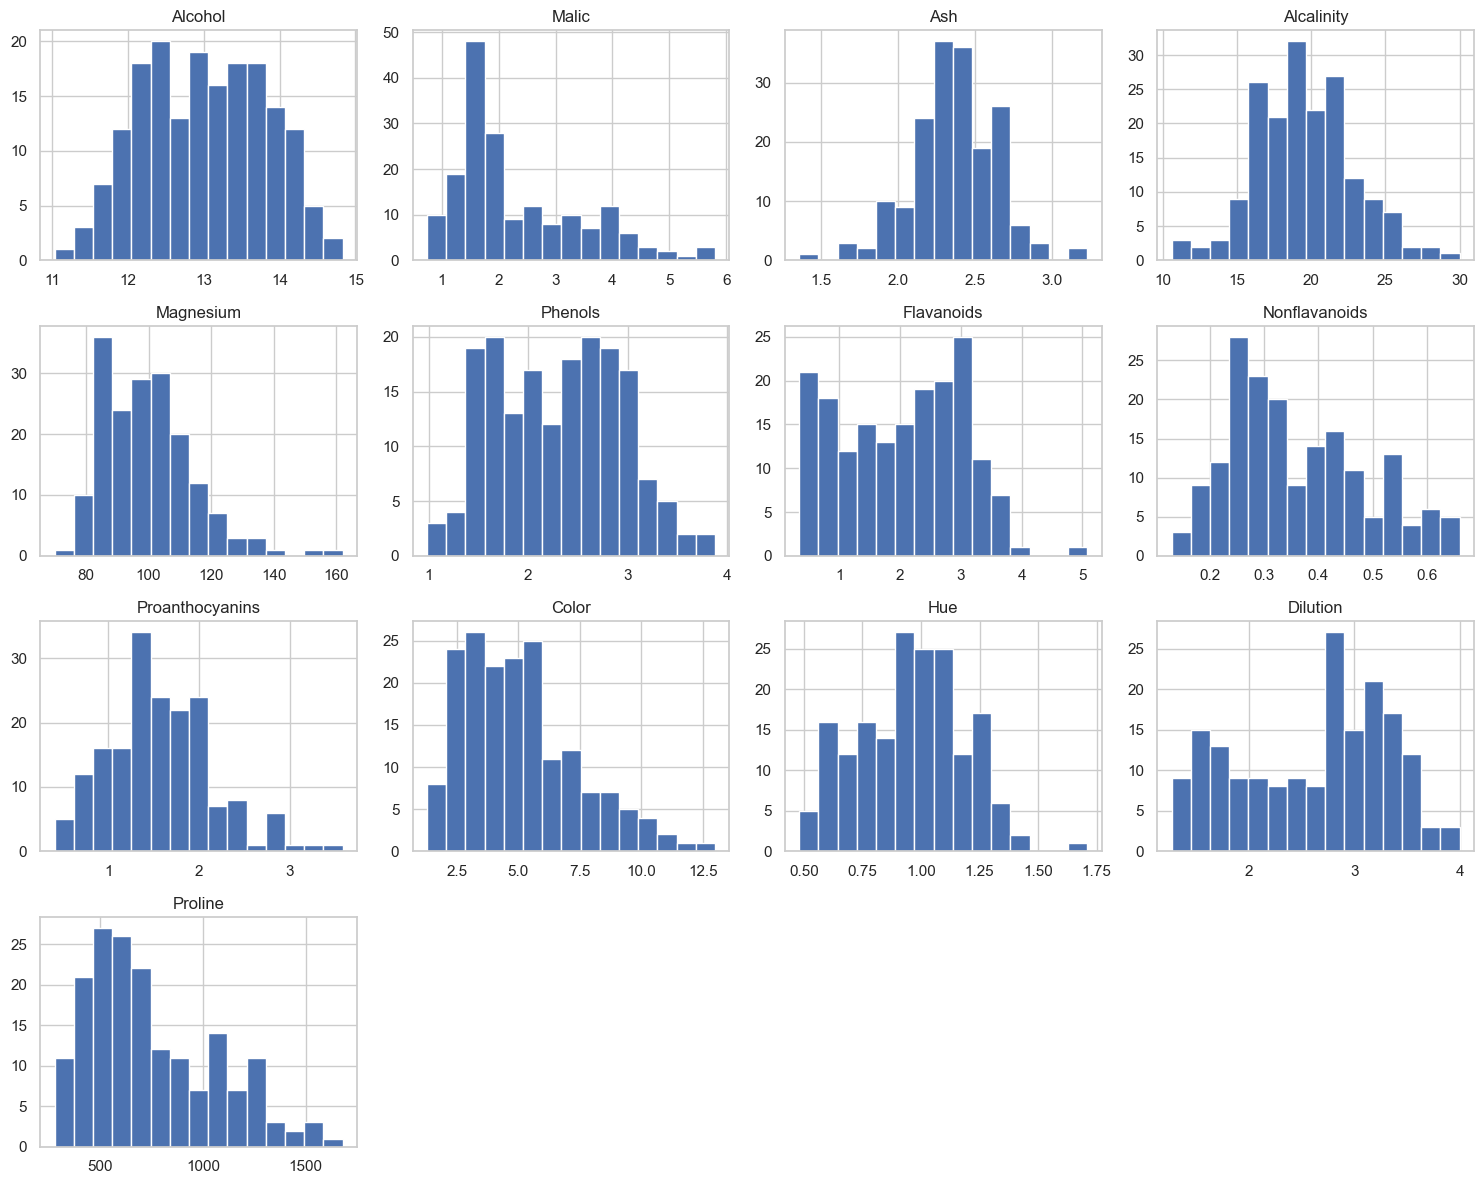

In [36]:
features = df.drop(columns=["Type"])

features.hist(figsize=(15, 12), bins=15)
plt.tight_layout()
plt.show()

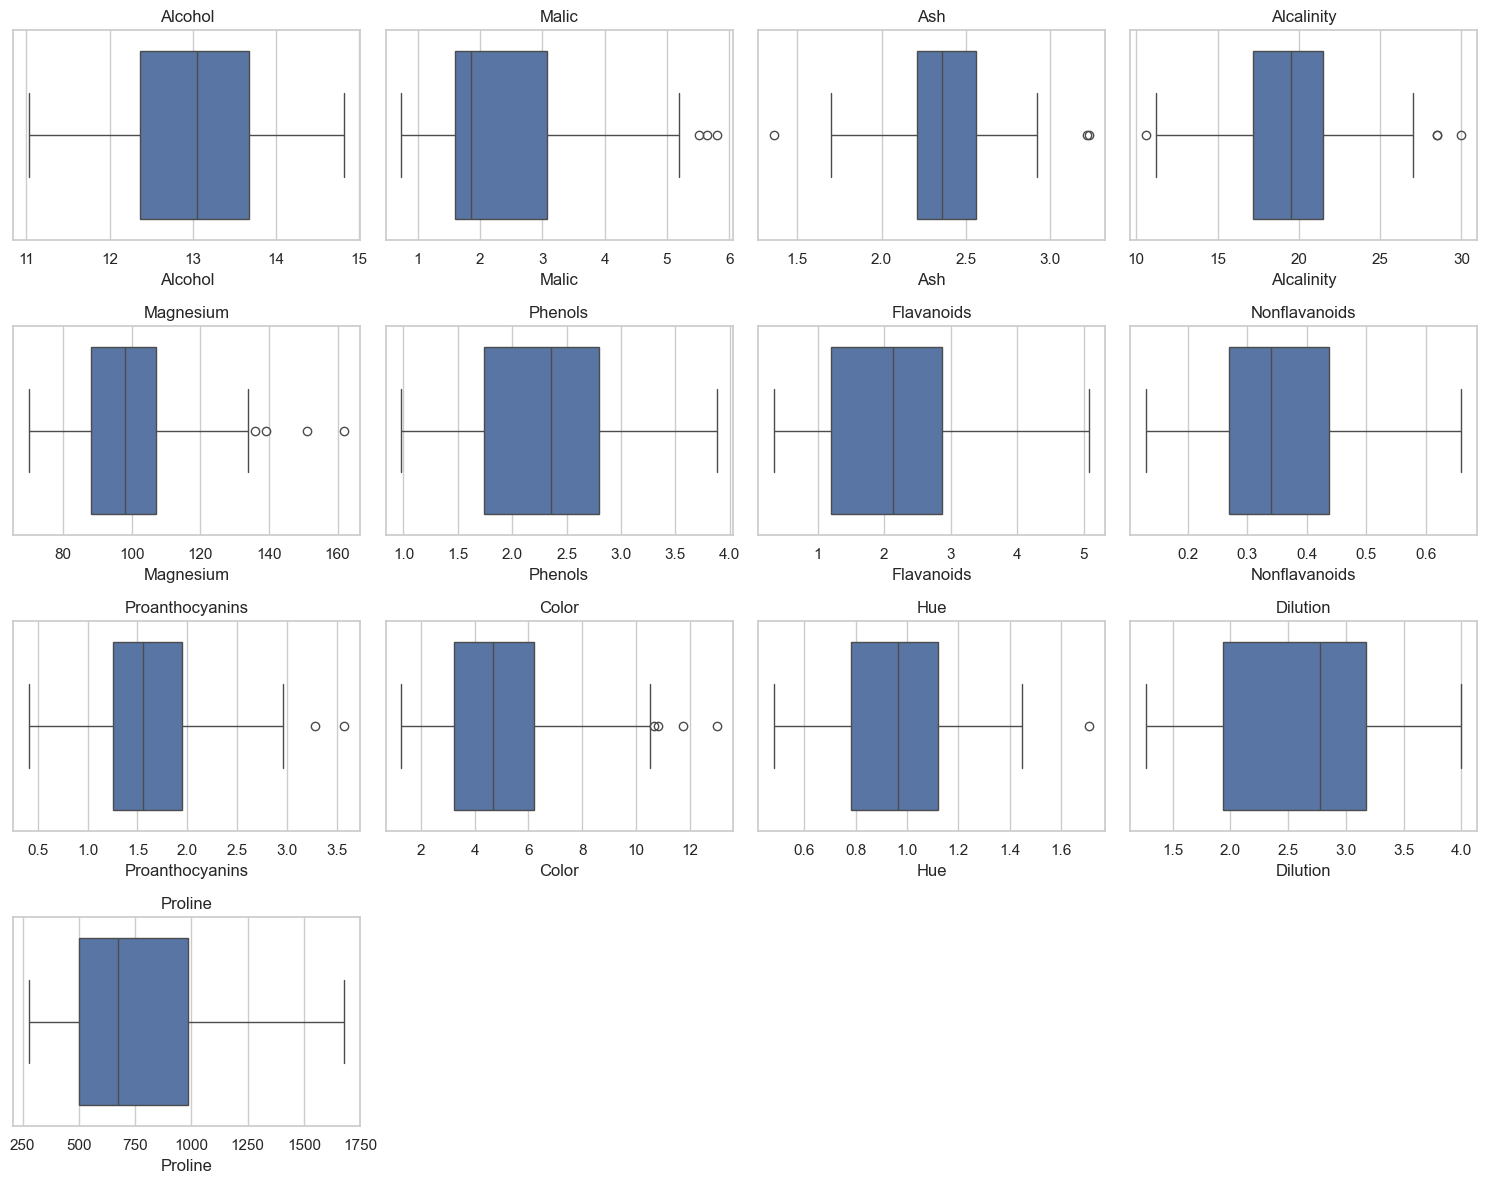

In [37]:
fig, axes = plt.subplots(4, 4, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(features.columns):
    sns.boxplot(x=features[col], ax=axes[i])
    axes[i].set_title(col)

for i in range(len(features.columns), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

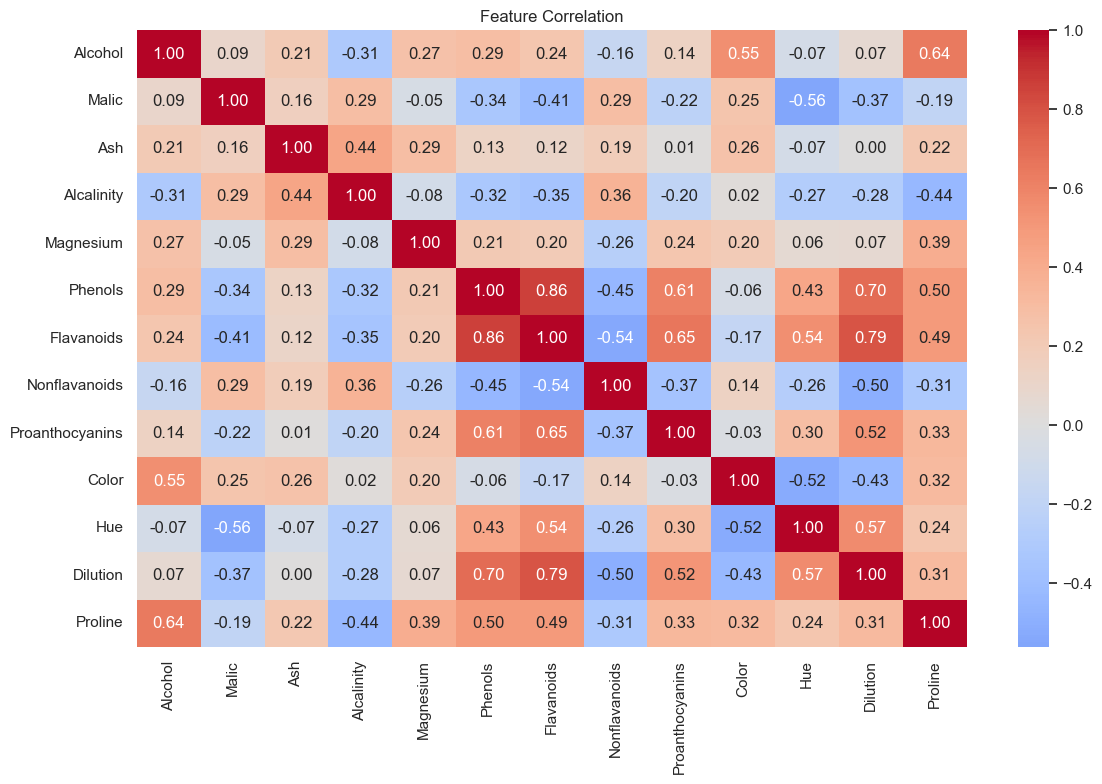

In [38]:
plt.figure(figsize=(12, 8))
sns.heatmap(features.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

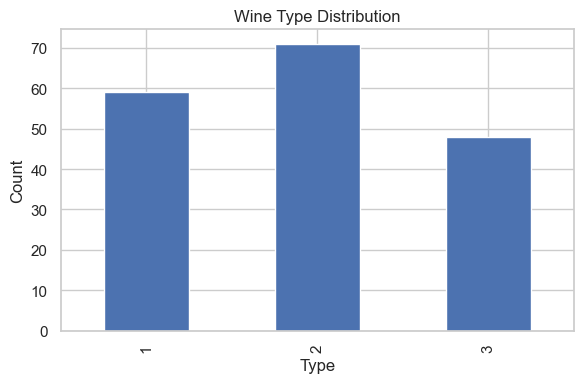

In [39]:
df["Type"].value_counts().sort_index().plot(kind="bar", figsize=(6, 4))
plt.title("Wine Type Distribution")
plt.xlabel("Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## Preprocessing

In [40]:
df = df.drop_duplicates().reset_index(drop=True)
df[features.columns] = df[features.columns].fillna(df[features.columns].median())

X = df.drop(columns=["Type"])
y = df["Type"]

print("Missing values after handling:", X.isnull().sum().sum())
print("Rows and features:", X.shape)

Missing values after handling: 0
Rows and features: (178, 13)


In [41]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Mean of first three scaled features:", X_scaled.mean(axis=0)[:3].round(3))
print("Standard deviation of first three scaled features:", X_scaled.std(axis=0)[:3].round(3))

Mean of first three scaled features: [-0. -0. -0.]
Standard deviation of first three scaled features: [1. 1. 1.]


## PCA

In [42]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

variance = pd.DataFrame({
    "Component": np.arange(1, len(pca_full.explained_variance_ratio_) + 1),
    "Explained Variance": pca_full.explained_variance_ratio_,
    "Cumulative Variance": np.cumsum(pca_full.explained_variance_ratio_)
})

variance.round(3)

,Component,Explained Variance,Cumulative Variance
0,1,0.362,0.362
1,2,0.192,0.554
2,3,0.111,0.665
3,4,0.071,0.736
4,5,0.066,0.802
5,6,0.049,0.851
6,7,0.042,0.893
7,8,0.027,0.920
8,9,0.022,0.942
9,10,0.019,0.962


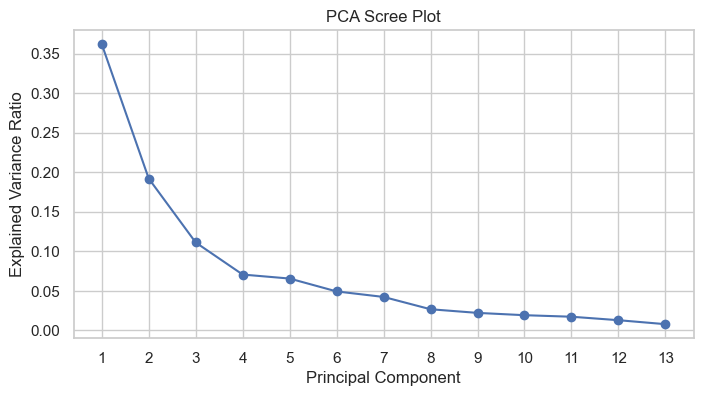

In [43]:
plt.figure(figsize=(8, 4))
plt.plot(variance["Component"], variance["Explained Variance"], marker="o")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.xticks(variance["Component"])
plt.show()

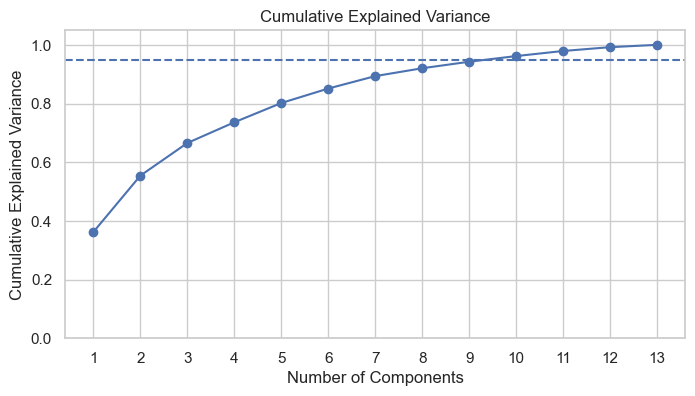

In [44]:
plt.figure(figsize=(8, 4))
plt.plot(variance["Component"], variance["Cumulative Variance"], marker="o")
plt.axhline(0.95, linestyle="--")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.xticks(variance["Component"])
plt.ylim(0, 1.05)
plt.show()

In [45]:
n_components = int(np.argmax(np.cumsum(pca_full.explained_variance_ratio_) >= 0.95) + 1)
print("Components needed for at least 95% variance:", n_components)
print("Variance retained:", round(np.cumsum(pca_full.explained_variance_ratio_)[n_components - 1], 3))

Components needed for at least 95% variance: 10
Variance retained: 0.962


In [46]:
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=[f"PC{i}" for i in range(1, n_components + 1)]
)

pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,3.316751,1.443463,-0.165739,-0.215631,0.693043,0.223880,0.596427,-0.065139,-0.641443,1.020956
1,2.209465,-0.333393,-2.026457,-0.291358,-0.257655,0.927120,0.053776,-1.024416,0.308847,0.159701
2,2.516740,1.031151,0.982819,0.724902,-0.251033,-0.549276,0.424205,0.344216,1.177834,0.113361
3,3.757066,2.756372,-0.176192,0.567983,-0.311842,-0.114431,-0.383337,-0.643593,-0.052544,0.239413
4,1.008908,0.869831,2.026688,-0.409766,0.298458,0.406520,0.444074,-0.416700,-0.326819,-0.078366


## K-means clustering

In [47]:
n_clusters = df["Type"].nunique()

kmeans_original = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters_original = kmeans_original.fit_predict(X_scaled)

kmeans_pca = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clusters_pca = kmeans_pca.fit_predict(X_pca)

print("Number of clusters:", n_clusters)

Number of clusters: 3


In [48]:
results = pd.DataFrame({
    "Dataset": ["Original scaled features", "PCA features"],
    "Silhouette Score": [
        silhouette_score(X_scaled, clusters_original),
        silhouette_score(X_pca, clusters_pca)
    ],
    "Davies-Bouldin Index": [
        davies_bouldin_score(X_scaled, clusters_original),
        davies_bouldin_score(X_pca, clusters_pca)
    ],
    "Adjusted Rand Index vs Type": [
        adjusted_rand_score(y, clusters_original),
        adjusted_rand_score(y, clusters_pca)
    ]
})

print(results.round(3).to_string(index=False))

                 Dataset  Silhouette Score  Davies-Bouldin Index  Adjusted Rand Index vs Type
Original scaled features             0.285                 1.389                        0.897
            PCA features             0.299                 1.336                        0.897


In [49]:
print("Original feature cluster counts:")
print(pd.Series(clusters_original).value_counts().sort_index())

print("\nPCA feature cluster counts:")
print(pd.Series(clusters_pca).value_counts().sort_index())

Original feature cluster counts:
0    65
1    51
2    62
Name: count, dtype: int64

PCA feature cluster counts:
0    65
1    51
2    62
Name: count, dtype: int64


## Cluster visualizations

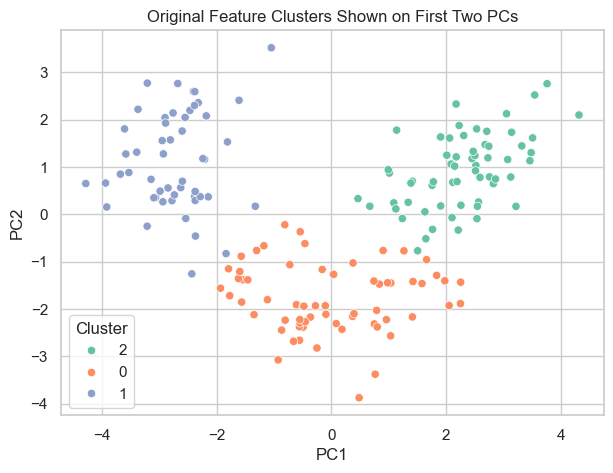

In [50]:
plot_original = pd.DataFrame({
    "PC1": X_pca_full[:, 0],
    "PC2": X_pca_full[:, 1],
    "Cluster": clusters_original.astype(str)
})

plt.figure(figsize=(7, 5))
sns.scatterplot(data=plot_original, x="PC1", y="PC2", hue="Cluster", palette="Set2")
plt.title("Original Feature Clusters Shown on First Two PCs")
plt.show()

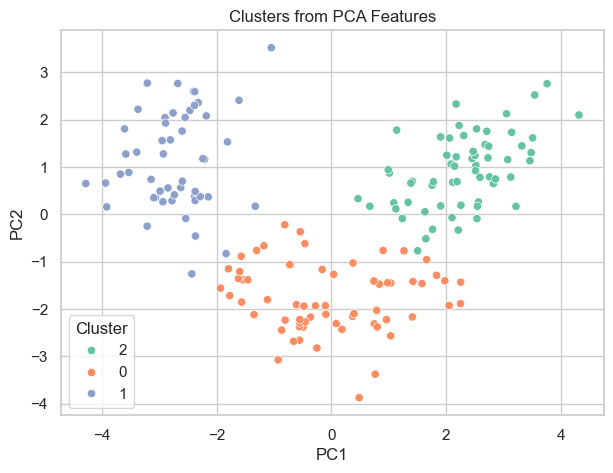

In [51]:
plot_pca = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": clusters_pca.astype(str)
})

plt.figure(figsize=(7, 5))
sns.scatterplot(data=plot_pca, x="PC1", y="PC2", hue="Cluster", palette="Set2")
plt.title("Clusters from PCA Features")
plt.show()

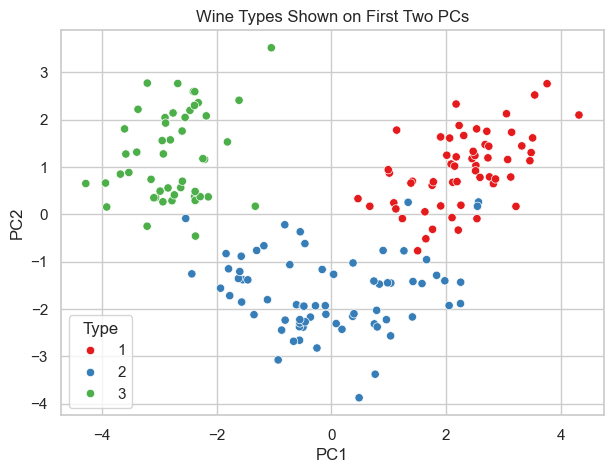

In [52]:
plot_type = pd.DataFrame({
    "PC1": X_pca_full[:, 0],
    "PC2": X_pca_full[:, 1],
    "Type": y.astype(str)
})

plt.figure(figsize=(7, 5))
sns.scatterplot(data=plot_type, x="PC1", y="PC2", hue="Type", palette="Set1")
plt.title("Wine Types Shown on First Two PCs")
plt.show()

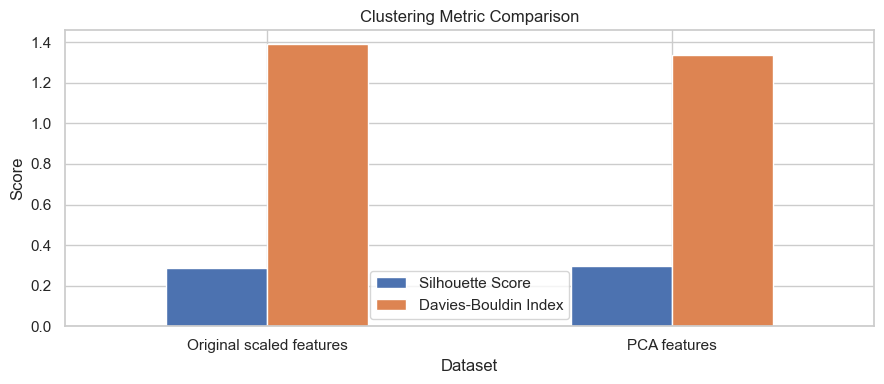

In [53]:
metrics_plot = results.set_index("Dataset")[["Silhouette Score", "Davies-Bouldin Index"]]
metrics_plot.plot(kind="bar", figsize=(9, 4))
plt.title("Clustering Metric Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Comparison and conclusion

A higher silhouette score generally means clusters are better separated. A lower Davies-Bouldin index generally means clusters are more compact and distinct. The adjusted Rand index compares the cluster assignments with the known `Type` labels; it is included only for comparison after clustering, not as an input to K-means.

In [54]:
best_silhouette = results.loc[results["Silhouette Score"].idxmax(), "Dataset"]
best_davies = results.loc[results["Davies-Bouldin Index"].idxmin(), "Dataset"]
best_ari = results.loc[results["Adjusted Rand Index vs Type"].idxmax(), "Dataset"]

print("Dataset with the higher silhouette score:", best_silhouette)
print("Dataset with the lower Davies-Bouldin index:", best_davies)
print("Dataset with the higher agreement with Type labels:", best_ari)
print("Number of PCA components used:", n_components)

Dataset with the higher silhouette score: PCA features
Dataset with the lower Davies-Bouldin index: PCA features
Dataset with the higher agreement with Type labels: Original scaled features
Number of PCA components used: 10
